# Домашнее задание 1. Персональные top-10 рекомендации

**Студент:** Кочарян Ованес Ромикович.

**Данные:** [Amazon Review Data (2018), Digital Music](https://nijianmo.github.io/amazon/index.html).

**Задача:** рекомендовать ранее не оценённые музыкальные товары из фиксированного каталога.
Релевантность на validation и test: первая наблюдаемая оценка пользователя товару **не ниже 4 из 5**.
Отзыв рассматривается как наблюдаемый интерес, но не как достоверная покупка или прослушивание.

## 1. Загрузка и описание данных

Запуск из папки `Homework_1` на Python 3.9–3.12: `python3 -m venv .venv`,
затем `.venv/bin/python -m pip install -r requirements.txt` и
`.venv/bin/python scripts/run_notebook.py`.
Для ручной работы: `.venv/bin/python -m jupyter notebook experiments.ipynb`
(интерфейс устанавливается отдельно: `.venv/bin/python -m pip install notebook`).
Первые ячейки автоматически скачивают два файла при их отсутствии. Повторный запуск проверяет SHA-256.
Исходные данные, окружение и кеши исключены из Git через `.gitignore`.

Исходные поля CSV: `item_id` (ASIN товара), `user_id` (анонимный ID), `rating` (1–5),
`timestamp` (Unix time в секундах UTC). В JSONL метаданных:
`asin`, `title` (название), `brand` (исполнитель/издатель), `category` (категории).
Метаданные соединяются по ASIN; пропуски сохраняются явно.

In [1]:
import os
from pathlib import Path
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS']:
    os.environ[name] = '1'
os.environ['MPLCONFIGDIR'] = str(Path('tmp/matplotlib').resolve())
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits, threadpool_info
from recsys.data import download_data, load_dataset, SOURCE, TRAIN_END, VALID_END, N_ITEMS, MIN_TRAIN_EVENTS
from recsys.experiment import tune, final_comparison, ablations, SEARCH_SPACE, SEED, PRIMARY_METRIC
from recsys.evaluation import make_protocol
from models import ItemKNN, IALS, EASE, FactorizationMachine, CustomTargetALS
%matplotlib inline
random.seed(SEED)
np.random.seed(SEED)
thread_limit = threadpool_limits(limits=1)
pd.set_option('display.max_colwidth', 150)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
Path('results').mkdir(exist_ok=True)
manifest = download_data()
Path('results/dataset_manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')
display(pd.DataFrame(manifest).T)

,url,bytes,sha256
Digital_Music.csv,https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Digital_Music.csv,66111451,a73f1504ed58fdc3533a6817b4c89fc4f722eb46dc18f94a4566a4b171439c9c
meta_Digital_Music.json.gz,https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Digital_Music.json.gz,12414214,c044fdd1804a4ff619764f1db47efdc28585d186392e9daf7fd42e3b6bb41559


In [2]:
bundle = load_dataset()
data, train, validation, test = [bundle[name] for name in ['data', 'train', 'validation', 'test']]
audit = bundle['audit']
Path('results/data_audit.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2, default=int) + '\n')
display(pd.DataFrame([
    {'stage': 'Исходный CSV', 'interactions': audit['raw_rows'], 'users': audit['raw_users'], 'items': audit['raw_items']},
    {'stage': 'После очистки, до отбора', 'interactions': audit['clean_rows_before_sampling'], 'users': None, 'items': None},
    {'stage': 'Итоговая выборка', 'interactions': audit['rows'], 'users': audit['users'], 'items': audit['items']},
]))
display(data[['user_id', 'item_id', 'rating', 'timestamp']].head())
display(bundle['items'].head())

,stage,interactions,users,items
0,Исходный CSV,1584082,840372.0,456992.0
1,"После очистки, до отбора",1516551,NaN,NaN
2,Итоговая выборка,112972,32738.0,6838.0


,user_id,item_id,rating,timestamp
384670,AT5BAY6AIIQTZ,B00FY3LLKG,4.0,898214400
615,A3OZ7NPMLVDYWY,555820690X,5.0,898300800
172007,A3OZ7NPMLVDYWY,B000THKEK0,5.0,898300800
20489,A2ZQXJD7YUIEHB,B000V63C4Y,5.0,899942400
190986,A36IFECCWACRCF,B000QQVET4,5.0,900374400


,item_id,item_idx,title,artist,categories
0,0001377647,0,Master Collection Volume One,John Michael Talbot,
1,0001388703,1,So You Wanna Go Back to Egypt,Keith Green,
2,0001526146,2,Early Works - Dallas Holm,Dallas Holm,
3,0001527134,3,Early Works - Don Francisco,Don Francisco,
4,0006920055,4,The Life: The Complete Recorded Trilogy on the Life of Christ,Michael Card,


## 2. EDA и подготовка

Очистка: удаление пропусков в обязательных полях и некорректных оценок/временных меток;
для каждой пары user–item остаётся первое событие. При совпадении времени порядок фиксирован
лексикографически по ID, затем по оценке. Последующая переоценка не изменяет прошлое наблюдение.

Подвыборка детерминирована: по событиям **до 01.01.2015 UTC** выбираются 7 000 наиболее
часто оценённых товаров (равенства по ASIN), затем пользователи с минимум двумя различными
товарами из этого каталога в train. Пустые в train товары удаляются. Сохраняются все события
этих пользователей и товаров. Каталог ограничен из-за квадратичной памяти EASE;
минимальная активность позволяет оценивать персональные рекомендации.
Отбор не зависит от будущих оценок и качества моделей. ID кодируются в отсортированном порядке.

In [3]:
display(pd.DataFrame({'missing': audit['missing']}))
display(pd.Series({key: audit[key] for key in ['exact_duplicates', 'invalid_rows', 'repeated_pairs',
                                               'raw_metadata_rows', 'duplicate_selected_metadata', 'sparsity']}, name='value').to_frame())
display(pd.DataFrame({'missing_items': audit['metadata_missing']}))
activity = data.groupby('user_idx').size()
popularity = data.groupby('item_idx').size()
display(pd.DataFrame({'user_activity': activity.describe(), 'item_popularity': popularity.describe()}))
print(f"Разреженность итоговой матрицы: {audit['sparsity']:.6%}")

,missing
item_id,0
user_id,0
rating,0
timestamp,0


,value
exact_duplicates,65645.000000
invalid_rows,0.000000
repeated_pairs,67531.000000
raw_metadata_rows,74347.000000
duplicate_selected_metadata,76.000000
sparsity,0.999495


,missing_items
title,6428
artist,6424
categories,6837


,user_activity,item_popularity
count,32738.000000,6838.000000
mean,3.450791,16.521205
std,4.286574,26.540391
min,2.000000,1.000000
25%,2.000000,6.000000
50%,2.000000,10.000000
75%,3.000000,17.000000
max,343.000000,900.000000


Разреженность итоговой матрицы: 99.949535%


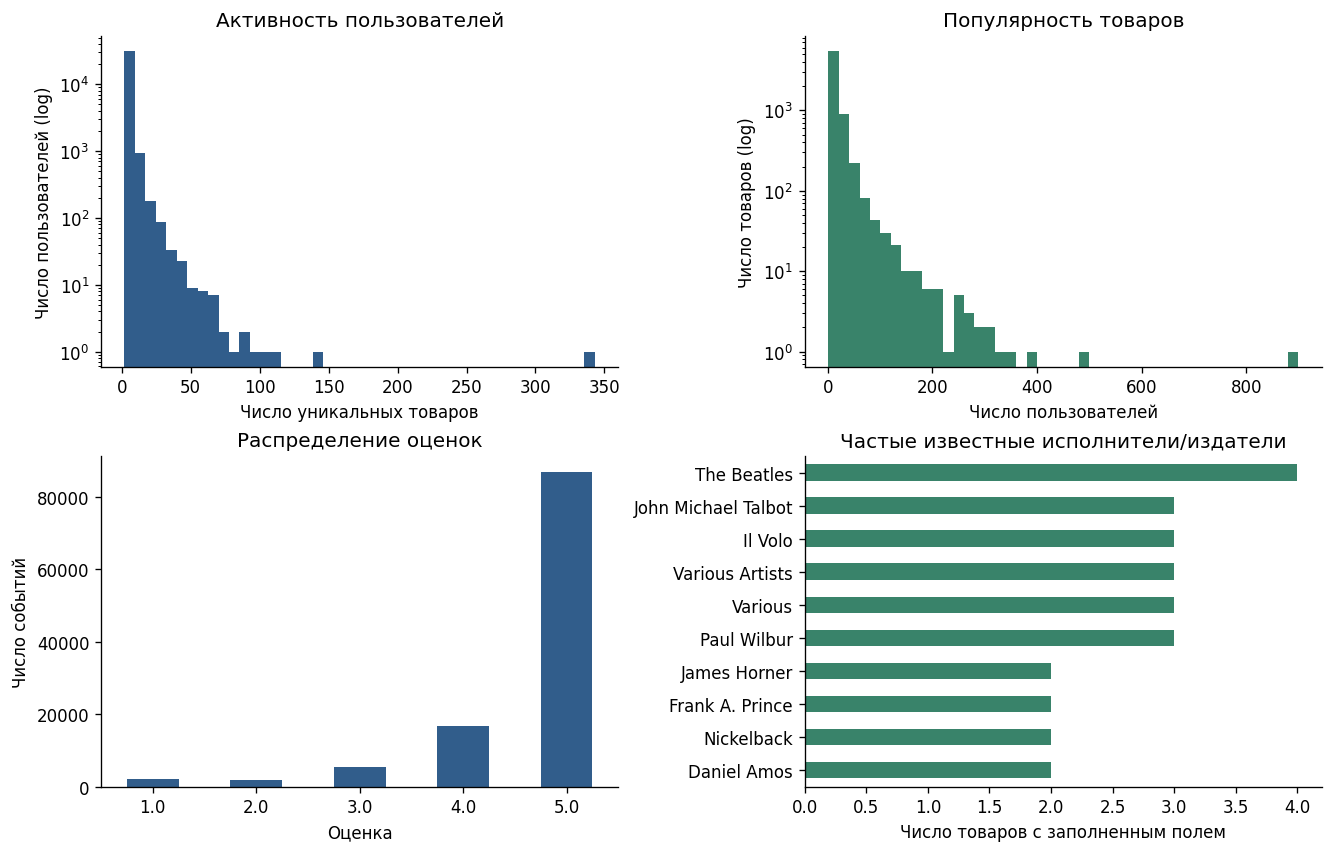

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
axes[0, 0].hist(activity, bins=45, color='#315d8b', log=True)
axes[0, 0].set(title='Активность пользователей', xlabel='Число уникальных товаров', ylabel='Число пользователей (log)')
axes[0, 1].hist(popularity, bins=45, color='#39836a', log=True)
axes[0, 1].set(title='Популярность товаров', xlabel='Число пользователей', ylabel='Число товаров (log)')
data.rating.value_counts().sort_index().plot.bar(ax=axes[1, 0], color='#315d8b', rot=0)
axes[1, 0].set(title='Распределение оценок', xlabel='Оценка', ylabel='Число событий')
train_artists = bundle['items'].loc[bundle['items'].artist.ne(''), 'artist'].value_counts().head(10)
train_artists.iloc[::-1].plot.barh(ax=axes[1, 1], color='#39836a')
axes[1, 1].set(title='Частые известные исполнители/издатели', xlabel='Число товаров с заполненным полем', ylabel='')
plt.show()
fig.savefig('results/eda.png', dpi=160, bbox_inches='tight')

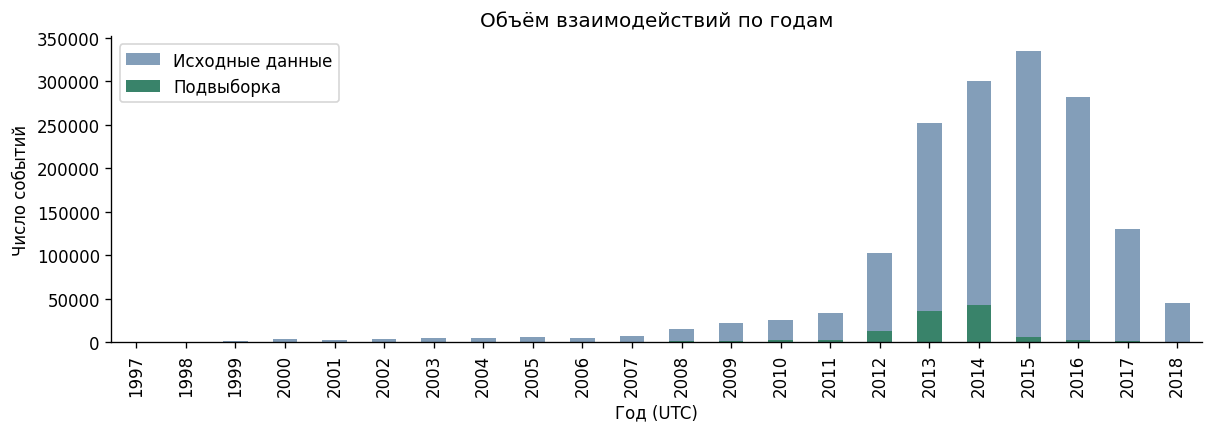

,categories
categories,
(нет данных),6837
Digital Music | Folk,1


In [5]:
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
bundle['raw_years'].plot.bar(ax=ax, color='#315d8b', alpha=.6, label='Исходные данные')
selected_years = pd.to_datetime(data.timestamp, unit='s', utc=True).dt.year.value_counts().sort_index()
selected_years.reindex(bundle['raw_years'].index, fill_value=0).plot.bar(ax=ax, color='#39836a', label='Подвыборка')
ax.set(title='Объём взаимодействий по годам', xlabel='Год (UTC)', ylabel='Число событий')
ax.legend()
plt.show()
display(pd.DataFrame({'categories': bundle['items'].categories.replace('', '(нет данных)').value_counts().head(10)}))

Цены, рейтинг популярности `rank`, графы `also_buy/also_view` и текст целевого отзыва исключены
из признаков: они могут содержать сведения из будущего или непосредственно о целевой оценке.
Название, исполнитель и категории используются для EDA и представления рекомендаций.
Выгрузка метаданных не содержит истории их изменения, поэтому даже статичные на вид поля
не передаются FM. Её дополнительные признаки строятся из timestamp и строго предыдущей истории.
Снимок внешних метаданных покрывает лишь небольшую часть выбранного каталога,
тогда как timestamp присутствует у всех событий. Временные метапризнаки устраняют
зависимость от неполного покрытия каталога. Число `repeated_pairs` включает точные
дубликаты, а не прибавляется к ним.

## 3. Протокол оценки

Глобальное временное разбиение: train — до 01.01.2015; validation — 2015 год;
test — с 01.01.2016 до конца источника. Все границы заданы в UTC заранее.
Validation оценивается по истории train; после выбора параметров модели обучаются заново на train+validation,
и test оценивается по истории до 01.01.2016. Внутри периода модель и история не обновляются.

Кандидаты каждого пользователя — **весь выбранный каталог** за вычетом всех ранее оценённых
товаров, включая низкие оценки; негативные кандидаты при оценке не семплируются.
Измеряется качество только для выбранных warm-start пользователей, имеющих хотя бы один
релевантный товар в соответствующем будущем периоде. Правило едино для пяти моделей,
но состав пользователей validation и test может различаться. Пользователи без будущих позитивов
не входят в среднее; это условная offline-оценка.

Новые пользователи, новые товары и товары вне выбранного каталога исключаются из эксперимента:
они требуют отдельного cold-start протокола. Объём исключений показан ниже;
причины могут пересекаться. Качество на всём исходном трафике не заявляется.

**Основная метрика, выбранная до подбора: NDCG@10.** Она учитывает позицию релевантного товара.
Дополнительная метрика Recall@10 показывает долю найденных релевантных товаров.
Обе усредняются по пользователям с равным весом. Coverage@10 — диагностическая доля каталога,
попавшая хотя бы в один список рекомендаций.

$$Recall@10=\frac1{|U|}\sum_u\frac{|L_u^{10}\cap R_u|}{|R_u|},$$
$$NDCG@10=\frac1{|U|}\sum_u
\frac{\sum_{j=1}^{10}\mathbb{1}[L_{u,j}\in R_u]/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

Релевантность test не меняется между моделями, в том числе при использовании другого train-таргета.
При равных score товары упорядочиваются по ASIN. Случайное зерно — 42, BLAS — один поток.

In [6]:
split_rows = []
for name in ['train', 'validation', 'test']:
    frame = bundle[name]
    split_rows.append({'split': name, 'events': len(frame), 'users': frame.user_idx.nunique(),
                       'items': frame.item_idx.nunique(), 'positive_share': frame.rating.ge(4).mean(),
                       'first_utc': str(pd.to_datetime(frame.timestamp.min(), unit='s', utc=True).date()),
                       'last_utc': str(pd.to_datetime(frame.timestamp.max(), unit='s', utc=True).date())})
display(pd.DataFrame(split_rows))
display(pd.DataFrame({name: audit[name + '_source_coverage'] for name in ['validation', 'test']}).T)
validation_protocol = make_protocol(train, validation, bundle['shape'], TRAIN_END)
print('Пользователей для validation:', len(validation_protocol['users']))
candidate_counts = bundle['shape'][1] - np.diff(validation_protocol['seen'].indptr)[validation_protocol['users']]
print('Число кандидатов на пользователя (min/median/max):',
      int(candidate_counts.min()), float(np.median(candidate_counts)), int(candidate_counts.max()))

,split,events,users,items,positive_share,first_utc,last_utc
0,train,103287,32738,6838,0.913900,1998-06-19,2014-12-31
1,validation,5806,2708,2753,0.930934,2015-01-01,2015-12-31
2,test,3879,1793,2279,0.937613,2016-01-01,2018-07-24


,source_events,unknown_selected_user_events,outside_catalog_events,retained_events
validation,323751,297322,255453,5806
test,449856,423228,382798,3879


Пользователей для validation: 2583
Число кандидатов на пользователя (min/median/max): 6517 6835.0 6836


## 4. Модели и подбор гиперпараметров

### 4.1. Item-based CF
Матрица $X_{ui}=\mathbb{1}[r_{ui}\ge4]$; неизвестные и низкие оценки дают ноль.
Для товаров $i,j$: $n_i=\sum_uX_{ui}$, $n_{ij}=\sum_uX_{ui}X_{uj}$,
$$s_{ij}=\frac{n_{ij}}{\sqrt{n_in_j}}\frac{n_{ij}}{n_{ij}+\beta},\quad s_{ii}=0.$$
Нулевые знаменатели означают нулевое сходство. Для каждого кандидата $j$ сохраняются $k$
ближайших соседей, $\hat y_{uj}=\sum_iX_{ui}s_{ij}$.
Это перенос положительных предпочтений между совместно оценёнными товарами.

### 4.2. Базовый iALS
Явные оценки переводятся в бинарное предпочтение $p_{ui}=\mathbb{1}[r_{ui}\ge4]$.
$M_{ui}=1$ для любой наблюдаемой оценки, $c_{ui}=1+\alpha M_{ui}$.
Для неизвестных пар $p_{ui}=0,c_{ui}=1$; для наблюдаемой низкой оценки $p_{ui}=0,c_{ui}=1+\alpha$.
$$\min_{P,Q}\sum_{u,i}c_{ui}(p_{ui}-P_u^TQ_i)^2+\lambda(\|P\|_F^2+\|Q\|_F^2).$$
Попеременные точные обновления:
$$P_u=(Q^TQ+\alpha\sum_{i\in O_u}Q_iQ_i^T+\lambda I)^{-1}
(1+\alpha)\sum_{i\in O_u}p_{ui}Q_i.$$
Для $Q_i$ используется симметричная формула. Решаются линейные системы; явное обращение не требуется.
Низкая оценка хранится как наблюдаемый нулевой таргет, а не как пропуск.

### 4.3. EASE
На той же бинарной положительной матрице:
$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\quad diag(B)=0.$$
При $G=(X^TX+\lambda I)^{-1}$ решение $B_{ij}=-G_{ij}/G_{jj}$ для $i\ne j$;
$B_{ii}=0$, $\hat Y=XB$. Нулевая диагональ исключает тривиальное копирование входа.

### 4.4. FM с метапризнаками
$$f(x)=b+w^Tx+\tfrac12\sum_{a=1}^d
\left[(\sum_jV_{ja}x_j)^2-\sum_jV_{ja}^2x_j^2\right].$$
Признаки: one-hot user ID, item ID, **месяц и день недели** момента запроса;
$\log(1+n_u)/\log101$ и $\log(1+n_i)/\log101$ — активность пользователя и популярность товара
строго до этого момента; $\log(1+age_i)/\log3651$ — возраст товара в днях с первого известного события.
В обучении события с тем же timestamp не входят в прошлое (`searchsorted(side='left')`).
При оценке используются только история fit и заранее известное время границы периода.
Признаки описывают сезонность, объём истории и стадию жизненного цикла товара;
они доступны в момент рекомендации и не содержат оценки целевого события.

Обучение: бинарная логистическая функция потерь; наблюдаемая оценка ≥4 даёт 1, остальные — 0.
На каждый положительный пример генерируется до одного равномерного отрицательного товара:
он уже встречался до timestamp примера и отсутствует во всей истории fit этого пользователя.
Неразрешённые после 30 попыток примеры пропускаются; validation/test при семплировании не используются.
Сэмплирование фиксировано внутри fit; прогноз — score FM, а не калиброванная вероятность.
Добавляется L2-штраф на параметры активных признаков, усреднённый по примерам.
Градиенты вычислены аналитически, обновления — собственный AdaGrad.
Полное ранжирование вычисляется точным разложением FM на пользовательскую и товарную группы признаков.

### 4.5. ALS с собственным целевым сигналом
Вместо бинарного $p_{ui}$ для наблюдаемой пары:
$$p^*_{ui}=\frac{r_{ui}-3}{2}\cdot2^{-(T-t_{ui})/(86400\cdot730)}.$$
Для неизвестной пары $p^*_{ui}=0$. $T$ — граница истории fit.
Оценки 1/2 дают отрицательное предпочтение, 3 — нейтральное, 4/5 — положительное;
период полураспада 730 дней ослабляет устаревшие предпочтения.
Изменяется **сам таргет**, включая знак, а $c_{ui}=1+20M_{ui}$ остаётся таким же, как у iALS.
Целевая функция и нормальные уравнения из пункта 4.2 используют $p^*$ вместо $p$.
Это проверяемая гипотеза об относительной ценности оценок и актуальности интереса.

Все пять методов, их обучение и предсказания реализованы в `models/` на NumPy/SciPy.
Общий `recommend` выполняет исключение истории и точный top-10.
Готовые рекомендательные библиотеки и готовые обучаемые алгоритмы не используются.

In [7]:
display(pd.DataFrame([{'model': name, 'configurations': len(grid),
                       'search': json.dumps(grid, ensure_ascii=False)} for name, grid in SEARCH_SPACE.items()]))
print('Основная метрика:', PRIMARY_METRIC)
print('Всего конфигураций:', sum(map(len, SEARCH_SPACE.values())))

,model,configurations,search
0,ItemKNN,4,"[{""neighbors"": 40, ""shrinkage"": 10.0}, {""neighbors"": 40, ""shrinkage"": 50.0}, {""neighbors"": 100, ""shrinkage"": 10.0}, {""neighbors"": 100, ""shrinkage""..."
1,iALS,4,"[{""factors"": 24, ""regularization"": 1.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}, {""factors"": 24, ""regularization"": 10.0, ""alpha"": 20.0, ""iter..."
2,EASE,3,"[{""regularization"": 20.0}, {""regularization"": 100.0}, {""regularization"": 500.0}]"
3,FM,4,"[{""factors"": 16, ""regularization"": 0.0001, ""learning_rate"": 0.05, ""epochs"": 12, ""batch_size"": 2048, ""metadata"": true, ""seed"": 42}, {""factors"": 16,..."
4,CustomALS,4,"[{""factors"": 24, ""regularization"": 1.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42, ""half_life_days"": 730.0}, {""factors"": 24, ""regularization"": 1..."


Основная метрика: NDCG@10
Всего конфигураций: 19


Сетки: ItemKNN — $k\in\{40,100\}$, $\beta\in\{10,50\}$;
iALS и CustomALS — размерность $\{24,48\}$, $\lambda\in\{1,10\}$,
confidence $\alpha=20$, 10 итераций; EASE — $\lambda\in\{20,100,500\}$;
FM — размерность $\{16,32\}$, L2 $\{10^{-4},10^{-3}\}$, шаг 0.05, 12 эпох, batch 2048.
Период полураспада кастомного сигнала 730 дней фиксирован.
Побеждает максимум validation NDCG@10; при равенстве — первая конфигурация сетки.
Выбранные параметры и все три диагностические абляции фиксируются в `results/selected.json` до обращения к test-метрикам.

In [8]:
validation_results, selected, validation_protocol = tune(bundle)
display(validation_results[['model', 'trial', 'NDCG@10', 'Recall@10', 'Coverage@10', 'fit_seconds', 'parameters']])
display(pd.DataFrame([{'model': name, 'selected_parameters': json.dumps(config, ensure_ascii=False)}
                      for name, config in selected.items()]))

ItemKNN 1/4: val NDCG@10=0.036546, Recall@10=0.054873, fit=0.1s


ItemKNN 2/4: val NDCG@10=0.036821, Recall@10=0.054565, fit=0.1s


ItemKNN 3/4: val NDCG@10=0.036669, Recall@10=0.054894, fit=0.1s


ItemKNN 4/4: val NDCG@10=0.036925, Recall@10=0.055010, fit=0.1s


/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: divide by zero encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: overflow encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: invalid value encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: divide by zero encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: overflow encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: invalid value encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:31: RuntimeWarning: div

...

CustomALS 2/4: val NDCG@10=0.031496, Recall@10=0.050445, fit=5.5s


CustomALS 3/4: val NDCG@10=0.036277, Recall@10=0.059834, fit=9.4s


CustomALS 4/4: val NDCG@10=0.035984, Recall@10=0.060030, fit=9.5s


,model,trial,NDCG@10,Recall@10,Coverage@10,fit_seconds,parameters
0,ItemKNN,1,0.036546,0.054873,0.730331,0.094292,"{""neighbors"": 40, ""shrinkage"": 10.0}"
1,ItemKNN,2,0.036821,0.054565,0.714975,0.085317,"{""neighbors"": 40, ""shrinkage"": 50.0}"
2,ItemKNN,3,0.036669,0.054894,0.721556,0.109051,"{""neighbors"": 100, ""shrinkage"": 10.0}"
3,ItemKNN,4,0.036925,0.055010,0.707956,0.108607,"{""neighbors"": 100, ""shrinkage"": 50.0}"
4,iALS,1,0.027611,0.043261,0.086868,5.454043,"{""alpha"": 20.0, ""factors"": 24, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}"
5,iALS,2,0.027243,0.042443,0.084674,5.554940,"{""alpha"": 20.0, ""factors"": 24, ""iterations"": 10, ""regularization"": 10.0, ""seed"": 42}"
6,iALS,3,0.033229,0.054384,0.169055,9.283000,"{""alpha"": 20.0, ""factors"": 48, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}"
7,iALS,4,0.032332,0.052968,0.162767,9.543864,"{""alpha"": 20.0, ""factors"": 48, ""iterations"": 10, ""regularization"": 10.0, ""seed"": 42}"
8,EASE,1,0.042227,0.061865,0.672273,13.738062,"{""regularization"": 20.0}"
9,EASE,2,0.041746,0.063368,0.591547,13.720749,"{""regularization"": 100.0}"


,model,selected_parameters
0,ItemKNN,"{""neighbors"": 100, ""shrinkage"": 50.0}"
1,iALS,"{""factors"": 48, ""regularization"": 1.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}"
2,EASE,"{""regularization"": 20.0}"
3,FM,"{""factors"": 32, ""regularization"": 0.0001, ""learning_rate"": 0.05, ""epochs"": 12, ""batch_size"": 2048, ""metadata"": true, ""seed"": 42}"
4,CustomALS,"{""factors"": 48, ""regularization"": 1.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42, ""half_life_days"": 730.0}"


## 5. Финальное сравнение при K = 10

Ниже test используется впервые для расчёта качества. Каждая модель с выбранными настройками
переобучается на train+validation. Результаты не используются для изменения настроек или протокола.
Время обучения измеряется отдельно от ранжирования; оно зависит от машины.

In [9]:
test_results, per_users, recommendations, fitted_models, test_protocol = final_comparison(bundle, selected)
print('Пользователей test:', len(test_protocol['users']))
display(test_results[['model', 'NDCG@10', 'Recall@10', 'Coverage@10', 'fit_seconds', 'evaluation_seconds', 'parameters']])

ItemKNN: test NDCG@10=0.021642, Recall@10=0.037150


/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: divide by zero encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: overflow encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: invalid value encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: divide by zero encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: overflow encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: invalid value encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:31: RuntimeWarning: div

/Users/kocharian-or/ml_2026/models/ials.py:47: RuntimeWarning: divide by zero encountered in matmul
  return self.user_factors[user_ids] @ self.item_factors.T
/Users/kocharian-or/ml_2026/models/ials.py:47: RuntimeWarning: overflow encountered in matmul
  return self.user_factors[user_ids] @ self.item_factors.T
/Users/kocharian-or/ml_2026/models/ials.py:47: RuntimeWarning: invalid value encountered in matmul
  return self.user_factors[user_ids] @ self.item_factors.T


iALS: test NDCG@10=0.020353, Recall@10=0.035755


EASE: test NDCG@10=0.022632, Recall@10=0.035445


...

/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: divide by zero encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: overflow encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: invalid value encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: divide by zero encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: overflow encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: invalid value encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:31: RuntimeWarning: div

/Users/kocharian-or/ml_2026/models/ials.py:47: RuntimeWarning: divide by zero encountered in matmul
  return self.user_factors[user_ids] @ self.item_factors.T
/Users/kocharian-or/ml_2026/models/ials.py:47: RuntimeWarning: overflow encountered in matmul
  return self.user_factors[user_ids] @ self.item_factors.T
/Users/kocharian-or/ml_2026/models/ials.py:47: RuntimeWarning: invalid value encountered in matmul
  return self.user_factors[user_ids] @ self.item_factors.T


CustomALS: test NDCG@10=0.019333, Recall@10=0.034781


Пользователей test: 1711


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds,evaluation_seconds,parameters
0,EASE,0.022632,0.035445,0.571220,13.671763,2.268641,"{""regularization"": 20.0}"
1,ItemKNN,0.021642,0.037150,0.612021,0.127482,0.178901,"{""neighbors"": 100, ""shrinkage"": 50.0}"
2,iALS,0.020353,0.035755,0.155601,9.340070,0.577810,"{""alpha"": 20.0, ""factors"": 48, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}"
3,CustomALS,0.019333,0.034781,0.161743,9.446442,0.612655,"{""alpha"": 20.0, ""factors"": 48, ""half_life_days"": 730.0, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}"
4,FM,0.010304,0.013331,0.008336,8.090035,0.602035,"{""batch_size"": 2048, ""epochs"": 12, ""factors"": 32, ""learning_rate"": 0.05, ""metadata"": true, ""regularization"": 0.0001, ""seed"": 42}"


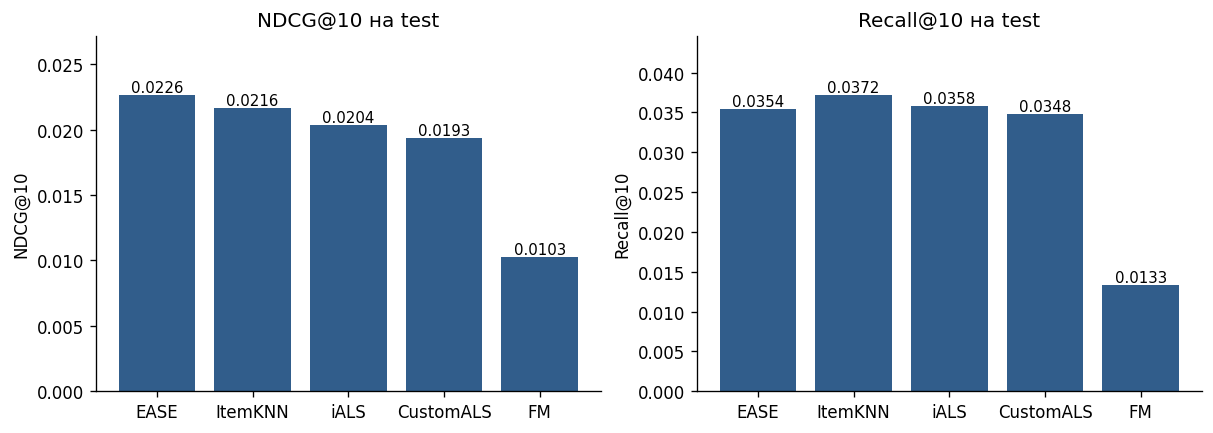

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    ax.bar(test_results.model, test_results[metric], color='#315d8b')
    ax.set(title=metric + ' на test', ylabel=metric)
    for i, value in enumerate(test_results[metric]):
        ax.text(i, value, f'{value:.4f}', ha='center', va='bottom', fontsize=9)
    ax.set_ylim(0, test_results[metric].max() * 1.2)
plt.show()
fig.savefig('results/comparison.png', dpi=160, bbox_inches='tight')

### Контролируемые абляции

FM без метаданных сравнивается с полной FM при тех же выбранных настройках, числе эпох и seed.
Для ALS отдельно фиксируются настройки победителя базового iALS и меняется только таргет:
бинарный, знаковая оценка без затухания, знаковая оценка с затуханием.
Это отделяет эффект сигнала от различий подобранных гиперпараметров.
Абляции диагностические: по их test-результатам модель не переобучается и настройки не выбираются.

Для разностей NDCG@10 рассчитан парный пользовательский bootstrap: 2 000 повторов,
seed 42, процентильный 95% интервал. Интервал отражает неопределённость набора пользователей
при фиксированных данных и обучении; он не учитывает вариацию по seed и зависимость пользователей.

/Users/kocharian-or/ml_2026/models/fm.py:179: RuntimeWarning: divide by zero encountered in matmul
  return self.bias + ub[:, None] + ib[None, :] + uv @ iv.T
/Users/kocharian-or/ml_2026/models/fm.py:179: RuntimeWarning: overflow encountered in matmul
  return self.bias + ub[:, None] + ib[None, :] + uv @ iv.T
/Users/kocharian-or/ml_2026/models/fm.py:179: RuntimeWarning: invalid value encountered in matmul
  return self.bias + ub[:, None] + ib[None, :] + uv @ iv.T


Ablation FM_ID_only: NDCG@10=0.008333


/Users/kocharian-or/ml_2026/models/ials.py:47: RuntimeWarning: divide by zero encountered in matmul
  return self.user_factors[user_ids] @ self.item_factors.T
/Users/kocharian-or/ml_2026/models/ials.py:47: RuntimeWarning: overflow encountered in matmul
  return self.user_factors[user_ids] @ self.item_factors.T
/Users/kocharian-or/ml_2026/models/ials.py:47: RuntimeWarning: invalid value encountered in matmul
  return self.user_factors[user_ids] @ self.item_factors.T


Ablation CustomALS_matched: NDCG@10=0.019333


/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: divide by zero encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: overflow encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:20: RuntimeWarning: invalid value encountered in matmul
  base = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: divide by zero encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: overflow encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:30: RuntimeWarning: invalid value encountered in matmul
  lhs = base + self.alpha * (local.T @ local)
/Users/kocharian-or/ml_2026/models/ials.py:31: RuntimeWarning: div

Ablation SignedALS_no_decay: NDCG@10=0.019939


,model,NDCG@10,Recall@10,Coverage@10,parameters
0,FM_ID_only,0.008333,0.014078,0.114946,"{""batch_size"": 2048, ""epochs"": 12, ""factors"": 32, ""learning_rate"": 0.05, ""metadata"": false, ""regularization"": 0.0001, ""seed"": 42}"
1,CustomALS_matched,0.019333,0.034781,0.161743,"{""alpha"": 20.0, ""factors"": 48, ""half_life_days"": 730.0, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}"
2,SignedALS_no_decay,0.019939,0.033823,0.153261,"{""alpha"": 20.0, ""factors"": 48, ""half_life_days"": Infinity, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}"


,comparison,difference,ci_low,ci_high,users
0,CustomALS - iALS,-0.001020,-0.005198,0.003213,1711
1,CustomALS_matched - iALS,-0.001020,-0.005198,0.003213,1711
2,CustomALS_matched - SignedALS_no_decay,-0.000606,-0.004455,0.003102,1711
3,FM - FM_ID_only,0.001971,-0.002605,0.006375,1711


Отрицательных примеров в финальной FM: 99798


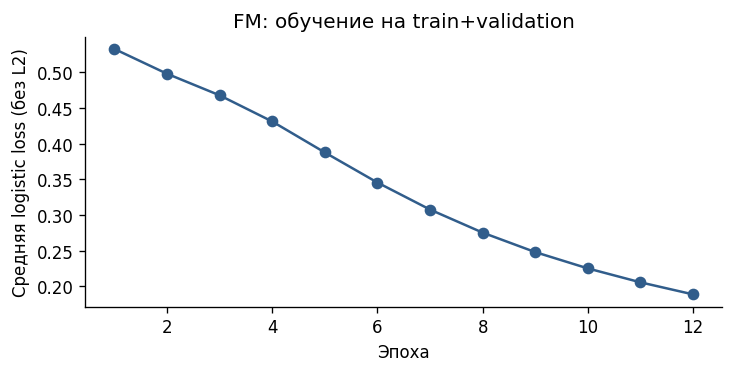

In [11]:
ablation_results, confidence_intervals = ablations(bundle, selected, fitted_models, per_users, test_protocol)
display(ablation_results)
display(confidence_intervals)
fm = fitted_models['FM']
print('Отрицательных примеров в финальной FM:', fm.negative_count)
fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.plot(np.arange(1, len(fm.loss_history) + 1), fm.loss_history, marker='o', color='#315d8b')
ax.set(title='FM: обучение на train+validation', xlabel='Эпоха', ylabel='Средняя logistic loss (без L2)')
plt.show()

In [12]:
# Два пользователя с наиболее длинной доступной историей среди test-когорты.
history_length = bundle['train_validation'].groupby('user_idx').size()
example_users = sorted(test_protocol['users'], key=lambda u: (-history_length.loc[u], int(u)))[:2]
best_model = test_results.iloc[0]['model']
examples = []
item_lookup = bundle['items'].set_index('item_idx')
for user in example_users:
    position = int(np.searchsorted(test_protocol['users'], user))
    for rank, item in enumerate(recommendations[best_model][position], 1):
        info = item_lookup.loc[item]
        examples.append({'user_idx': int(user), 'rank': rank, 'ASIN': info.item_id,
                         'title': info.title or '(название отсутствует)', 'artist': info.artist,
                         'relevant_in_test': int(item in test_protocol['truth'][int(user)])})
print('Примеры рекомендаций модели:', best_model)
display(pd.DataFrame(examples))
pd.DataFrame(examples).to_csv('results/recommendation_examples.csv', index=False)

Примеры рекомендаций модели: EASE


,user_idx,rank,ASIN,title,artist,relevant_in_test
0,25216,1,B00330WKMA,(название отсутствует),,0
1,25216,2,B006Z1XZFK,(название отсутствует),,0
2,25216,3,B005T18DOK,(название отсутствует),,0
3,25216,4,B00961ZGQC,(название отсутствует),,0
4,25216,5,B003VXHTG6,(название отсутствует),,0
5,25216,6,B00JJOG5D4,(название отсутствует),,0
6,25216,7,B00GG3OYMK,(название отсутствует),,0
7,25216,8,B0011Z77TA,(название отсутствует),,0
8,25216,9,B00GLP4DMO,(название отсутствует),,0
9,25216,10,B000V6TO82,(название отсутствует),,0


## 6. Выводы

In [13]:
winner = test_results.iloc[0]
ranked = test_results.set_index('model')
ab = ablation_results.set_index('model')
custom_delta = ranked.loc['CustomALS', 'NDCG@10'] - ranked.loc['iALS', 'NDCG@10']
matched_delta = ab.loc['CustomALS_matched', 'NDCG@10'] - ranked.loc['iALS', 'NDCG@10']
metadata_delta = ranked.loc['FM', 'NDCG@10'] - ab.loc['FM_ID_only', 'NDCG@10']
recall_winner = test_results.sort_values('Recall@10', ascending=False).iloc[0]
interval_lookup = confidence_intervals.set_index('comparison')
custom_ci = interval_lookup.loc['CustomALS_matched - iALS']
metadata_ci = interval_lookup.loc['FM - FM_ID_only']
decay_delta = ab.loc['CustomALS_matched', 'NDCG@10'] - ab.loc['SignedALS_no_decay', 'NDCG@10']
def interval_text(row):
    text = f"[{row['ci_low']:+.6f}; {row['ci_high']:+.6f}]"
    return text + (' (включает ноль)' if row['ci_low'] <= 0 <= row['ci_high'] else ' (не включает ноль)')
conclusion = (
    f"Лучшая модель по test NDCG@10: **{winner['model']}**, "
    f"NDCG@10 = **{winner['NDCG@10']:.6f}**, Recall@10 = **{winner['Recall@10']:.6f}**. "
    f"Её параметры: `{winner['parameters']}`.\n\n"
    f"После независимого подбора кастомный таргет изменил NDCG@10 относительно iALS на **{custom_delta:+.6f}**; "
    f"при одинаковых настройках базового ALS изменение составило **{matched_delta:+.6f}**. "
    f"Метапризнаки FM изменили NDCG@10 относительно ID-only FM на **{metadata_delta:+.6f}**. "
    f"Направление и неопределённость эффектов следует оценивать совместно с таблицей парных интервалов."
)
conclusion += chr(10) * 2 + (
    f"Наибольший Recall@10 у **{recall_winner['model']}**: **{recall_winner['Recall@10']:.6f}**. "
    f"95% интервал разности CustomALS и iALS при одинаковых настройках: **{interval_text(custom_ci)}**; "
    f"для метапризнаков FM: **{interval_text(metadata_ci)}**. "
    f"Преимущество кастомного сигнала на этих данных не подтверждено. "
    f"Затухание по сравнению со знаковыми оценками без затухания изменило NDCG@10 на **{decay_delta:+.6f}**."
)
conclusion += chr(10) * 2 + (
    f"Recall@10 полной FM = **{ranked.loc['FM', 'Recall@10']:.6f}**, "
    f"ID-only = **{ab.loc['FM_ID_only', 'Recall@10']:.6f}**; "
    f"покрытие каталога = **{ranked.loc['FM', 'Coverage@10']:.2%}** против "
    f"**{ab.loc['FM_ID_only', 'Coverage@10']:.2%}**. "
    f"Метапризнаки не обеспечили устойчивого улучшения по всем критериям; "
    f"FM уступила коллаборативным моделям при выбранных признаках и сетке."
)
display(Markdown(conclusion))
Path('results/conclusions.md').write_text(conclusion + '\n', encoding='utf-8')

Лучшая модель по test NDCG@10: **EASE**, NDCG@10 = **0.022632**, Recall@10 = **0.035445**. Её параметры: `{"regularization": 20.0}`.

После независимого подбора кастомный таргет изменил NDCG@10 относительно iALS на **-0.001020**; при одинаковых настройках базового ALS изменение составило **-0.001020**. Метапризнаки FM изменили NDCG@10 относительно ID-only FM на **+0.001971**. Направление и неопределённость эффектов следует оценивать совместно с таблицей парных интервалов.

Наибольший Recall@10 у **ItemKNN**: **0.037150**. 95% интервал разности CustomALS и iALS при одинаковых настройках: **[-0.005198; +0.003213] (включает ноль)**; для метапризнаков FM: **[-0.002605; +0.006375] (включает ноль)**. Преимущество кастомного сигнала на этих данных не подтверждено. Затухание по сравнению со знаковыми оценками без затухания изменило NDCG@10 на **-0.000606**.

Recall@10 полной FM = **0.013331**, ID-only = **0.014078**; покрытие каталога = **0.83%** против **11.49%**. Метапризнаки не обеспечили устойчивого улучшения по всем критериям; FM уступила коллаборативным моделям при выбранных признаках и сетке.

1109

**Ограничения.** Подвыборка смещена к активным до 2015 года пользователям и популярным товарам;
результаты не распространяются на cold-start и полный каталог. Test содержит только пользователей
с будущими позитивами. Отзыв не равен покупке; отсутствие отзыва не доказывает отрицательное отношение.
Изменение интереса, экспозиция и фактическая доступность товаров не наблюдаются.
Первая известная оценка задаёт лишь нижнюю границу наблюдаемого возраста товара, а не дату выпуска.
Горизонты validation и test различны; один список в начале многолетнего test упрощает реальную выдачу.
Проверены небольшие сетки и один seed; причинный эффект метаданных по такой offline-оценке не устанавливается.
Сезонность на обучающих событиях и календарь одного запроса на границе периода могут давать разный сигнал.

**Источники.**
[Ni, Li, McAuley, 2019 — описание данных](https://nijianmo.github.io/amazon/index.html);
[статья о датасете](https://aclanthology.org/D19-1018/);
[Hu, Koren, Volinsky, 2008 — iALS](https://yifanhu.net/PUB/cf.pdf);
[Steck, 2019 — EASE](https://arxiv.org/abs/1905.03375);
[Rendle, 2010 — FM](https://doi.org/10.1109/ICDM.2010.127).
ItemKNN и кастомный таргет заданы приведёнными выше формулами; исходный код моделей написан самостоятельно.